<div style="border-left: 6px solid #2f6fed; padding: 16px 22px; margin: 8px 0; border-radius: 6px; background: rgba(47, 111, 237, 0.08);">

<h1 style="margin: 0 0 6px 0;">Rental Properties: Data Cleaning</h1>

<p style="margin: 0; font-size: 1.05em;">
Prepares the raw rental listings dataset for modelling. It inspects the data, removes unneeded fields, fixes missing values, unpacks nested columns and saves a model-ready CSV.
</p>

</div>

<br>

<table style="width: 100%; border-collapse: collapse;">
  <tr>
    <td style="width: 50%; padding: 12px 16px; border: 1px solid rgba(128,128,128,0.35); vertical-align: top;">
      <b>Input</b><br>
      <code>../data/properties_db/properties.csv</code>
    </td>
    <td style="width: 50%; padding: 12px 16px; border: 1px solid rgba(128,128,128,0.35); vertical-align: top;">
      <b>Output</b><br>
      <code>../data/preprocessed_data/cleaned_properties.csv</code>
    </td>
  </tr>
</table>

<h3 style="margin-top: 24px;">What this notebook does</h3>

<table style="width: 100%; border-collapse: collapse;">
  <tr style="background: rgba(47, 111, 237, 0.15);">
    <th style="width: 6%; padding: 8px 12px; text-align: center; border: 1px solid rgba(128,128,128,0.35);">#</th>
    <th style="width: 22%; padding: 8px 12px; text-align: left; border: 1px solid rgba(128,128,128,0.35);">Stage</th>
    <th style="padding: 8px 12px; text-align: left; border: 1px solid rgba(128,128,128,0.35);">Details</th>
  </tr>
  <tr>
    <td style="padding: 8px 12px; text-align: center; border: 1px solid rgba(128,128,128,0.35);">1</td>
    <td style="padding: 8px 12px; border: 1px solid rgba(128,128,128,0.35);"><b>Inspect</b></td>
    <td style="padding: 8px 12px; border: 1px solid rgba(128,128,128,0.35);">Checks missing values, data types and unique values, and plots the distribution of <code>weekly_rent_number</code>.</td>
  </tr>
  <tr>
    <td style="padding: 8px 12px; text-align: center; border: 1px solid rgba(128,128,128,0.35);">2</td>
    <td style="padding: 8px 12px; border: 1px solid rgba(128,128,128,0.35);"><b>Review outlier</b></td>
    <td style="padding: 8px 12px; border: 1px solid rgba(128,128,128,0.35);">The highest rent is a genuine Southbank listing, so it is kept. Its influence will be reassessed at the modelling stage.</td>
  </tr>
  <tr>
    <td style="padding: 8px 12px; text-align: center; border: 1px solid rgba(128,128,128,0.35);">3</td>
    <td style="padding: 8px 12px; border: 1px solid rgba(128,128,128,0.35);"><b>Drop and fill</b></td>
    <td style="padding: 8px 12px; border: 1px solid rgba(128,128,128,0.35);">Removes <code>state</code> (single value), <code>n_photos</code>, <code>added_at</code>, <code>activated_at</code> and <code>url</code>. Fills missing <code>ensuites</code> with 0 and drops the few rows (under 5%) with no <code>street_address</code>.</td>
  </tr>
  <tr>
    <td style="padding: 8px 12px; text-align: center; border: 1px solid rgba(128,128,128,0.35);">4</td>
    <td style="padding: 8px 12px; border: 1px solid rgba(128,128,128,0.35);"><b>Standardise</b></td>
    <td style="padding: 8px 12px; border: 1px solid rgba(128,128,128,0.35);">Relabels the suburb <i>Melbourne</i> as <i>CBD</i> and renames <code>id</code> to <code>property_id</code>.</td>
  </tr>
  <tr>
    <td style="padding: 8px 12px; text-align: center; border: 1px solid rgba(128,128,128,0.35);">5</td>
    <td style="padding: 8px 12px; border: 1px solid rgba(128,128,128,0.35);"><b>Unpack JSON</b></td>
    <td style="padding: 8px 12px; border: 1px solid rgba(128,128,128,0.35);">Splits <code>walkability_score</code> into <code>walk_score</code> and <code>transit_score</code>.</td>
  </tr>
  <tr>
    <td style="padding: 8px 12px; text-align: center; border: 1px solid rgba(128,128,128,0.35);">6</td>
    <td style="padding: 8px 12px; border: 1px solid rgba(128,128,128,0.35);"><b>Validate</b></td>
    <td style="padding: 8px 12px; border: 1px solid rgba(128,128,128,0.35);">Confirms there are no negative values in the numeric columns (rent, rooms, car spaces and scores).</td>
  </tr>
  <tr>
    <td style="padding: 8px 12px; text-align: center; border: 1px solid rgba(128,128,128,0.35);">7</td>
    <td style="padding: 8px 12px; border: 1px solid rgba(128,128,128,0.35);"><b>Encode features</b></td>
    <td style="padding: 8px 12px; border: 1px solid rgba(128,128,128,0.35);">Flattens the nested <code>features</code> field into one-hot columns named <code>category_value</code>.</td>
  </tr>
  <tr>
    <td style="padding: 8px 12px; text-align: center; border: 1px solid rgba(128,128,128,0.35);">8</td>
    <td style="padding: 8px 12px; border: 1px solid rgba(128,128,128,0.35);"><b>Export</b></td>
    <td style="padding: 8px 12px; border: 1px solid rgba(128,128,128,0.35);">Saves the cleaned dataset as a CSV for the modelling stage.</td>
  </tr>
</table>

</div>

In [1]:
import pandas as pd
import warnings
warnings.filterwarnings('ignore')
data = pd.read_csv('../data/properties_db/properties.csv').iloc[:, 1:]
data.head()

,id,url,latitude,longitude,street_address,suburb,postcode,state,activated_at,weekly_rent_number,...,car_spaces,furnished,partially_furnished,pets_allowed,long_term_lease,is_build_to_rent,features,n_photos,walkability_score,added_at
0,515812,https://www.rent.com.au/property/108-126-chape...,-37.869108,144.990422,"108/126 Chapel Street,",st kilda,3182,vic,2026-05-27T08:58:04.000+08:00,550.0,...,1,False,False,False,False,False,{},6,"{""id"": 328136, ""transit_category"": ""excellent_...",2026-09-08 01:20:50
1,802350,https://www.rent.com.au/property/24-barkly-pl-...,-37.802986,144.961405,"24 Barkly Place,",carlton,3053,vic,2026-06-25T07:42:51.000+08:00,360.0,...,0,False,False,False,False,False,"{""airconditioning"": [""split system"", ""air-cond...",14,"{""id"": 239384, ""transit_category"": ""riders_par...",2026-09-07 21:14:45
2,802356,https://www.rent.com.au/property/45-victoria-p...,-37.808700,144.984130,"45 Victoria Parade,",collingwood,3066,vic,2026-06-19T08:05:47.000+08:00,360.0,...,0,False,False,False,False,False,{},20,"{""id"": 66149, ""transit_category"": ""riders_para...",2026-09-07 21:36:57
3,802372,https://www.rent.com.au/property/116-130-main-...,-37.714742,145.060900,"116-130 Main Drive,",macleod,3085,vic,2026-01-27T07:04:43.000+08:00,250.0,...,0,False,False,False,False,False,{},12,"{""id"": 67020, ""transit_category"": ""good_transi...",2026-09-07 23:09:44
4,802379,https://www.rent.com.au/property/117-60-waverl...,-37.875928,145.046426,"117/60 Waverley Road,",malvern east,3145,vic,2026-05-01T14:55:39.000+08:00,540.0,...,0,False,False,False,False,False,{},12,"{""id"": 349530, ""transit_category"": ""excellent_...",2026-09-07 23:13:36


# Checking for missing values, unique values, etc.


In [2]:
print(f"Number of unique values in 'state': {data['state'].nunique()}")
data.isna().any()

Number of unique values in 'state': 1


id                     False
url                    False
latitude               False
longitude              False
street_address          True
suburb                 False
postcode               False
state                  False
activated_at            True
weekly_rent_number     False
property_type          False
bedrooms               False
bathrooms              False
ensuites                True
car_spaces             False
furnished              False
partially_furnished    False
pets_allowed            True
long_term_lease        False
is_build_to_rent       False
features               False
n_photos               False
walkability_score      False
added_at               False
dtype: bool

In [3]:
print(data.dtypes)

id                       int64
url                        str
latitude               float64
longitude              float64
street_address             str
suburb                     str
postcode                 int64
state                      str
activated_at               str
weekly_rent_number     float64
property_type              str
bedrooms                 int64
bathrooms                int64
ensuites               float64
car_spaces               int64
furnished                 bool
partially_furnished       bool
pets_allowed            object
long_term_lease           bool
is_build_to_rent          bool
features                   str
n_photos                 int64
walkability_score          str
added_at                   str
dtype: object


# Investigating `weekly_rent_number`

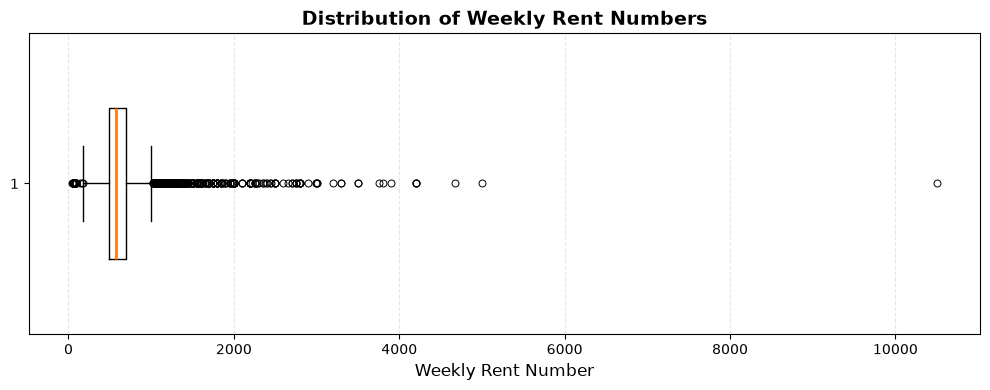

In [4]:
import matplotlib.pyplot as plt

# Create figure with appropriate size
plt.figure(figsize=(10, 4))

# Create boxplot with thicker lines
plt.boxplot(data['weekly_rent_number'], 
            orientation='horizontal',
            widths=0.5,
            boxprops=dict(linewidth=1),
            whiskerprops=dict(linewidth=1),
            capprops=dict(linewidth=1),
            medianprops=dict(linewidth=2),
            flierprops=dict(marker='o', markersize=5, markeredgewidth=0.7))

# Add labels and title
plt.xlabel('Weekly Rent Number', fontsize=12)
plt.title('Distribution of Weekly Rent Numbers', fontsize=14, fontweight='bold')

# Add grid behind the plot
plt.grid(True, axis='x', alpha=0.3, linestyle='--')

plt.tight_layout()
plt.show()

In [5]:
max_rent = data['weekly_rent_number'].max()
data.loc[data['weekly_rent_number'] == max_rent]

,id,url,latitude,longitude,street_address,suburb,postcode,state,activated_at,weekly_rent_number,...,car_spaces,furnished,partially_furnished,pets_allowed,long_term_lease,is_build_to_rent,features,n_photos,walkability_score,added_at
2138,6371480,https://www.rent.com.au/property/87-7-riversid...,-37.821335,144.964697,"87/7 Riverside Quay,",southbank,3006,vic,2026-05-08T11:27:48.000+08:00,10500.0,...,3,True,False,True,False,False,"{""airconditioning"": [""air-conditioning""], ""are...",30,"{""id"": 4596704, ""transit_category"": ""riders_pa...",2026-09-08 01:10:47


Searching online shows that the extreme outlier is a real rental property in Southbank. We choose to keep this value in our model on the basis that it is a valid rent value. However in the modelling stage, we will have to investigate whether this data point is worth keeping based on its influence.

# Performing the data cleaning steps

In [6]:
cleaned_data = data.copy()
# drop the 'state' column as it has only one unique value
cleaned_data.drop(columns=['state'], inplace=True)
# replace NULLs in 'ensuites' with 0
cleaned_data = cleaned_data.fillna({'ensuites': 0})
cleaned_data.head()

,id,url,latitude,longitude,street_address,suburb,postcode,activated_at,weekly_rent_number,property_type,...,car_spaces,furnished,partially_furnished,pets_allowed,long_term_lease,is_build_to_rent,features,n_photos,walkability_score,added_at
0,515812,https://www.rent.com.au/property/108-126-chape...,-37.869108,144.990422,"108/126 Chapel Street,",st kilda,3182,2026-05-27T08:58:04.000+08:00,550.0,Apartment,...,1,False,False,False,False,False,{},6,"{""id"": 328136, ""transit_category"": ""excellent_...",2026-09-08 01:20:50
1,802350,https://www.rent.com.au/property/24-barkly-pl-...,-37.802986,144.961405,"24 Barkly Place,",carlton,3053,2026-06-25T07:42:51.000+08:00,360.0,Studio,...,0,False,False,False,False,False,"{""airconditioning"": [""split system"", ""air-cond...",14,"{""id"": 239384, ""transit_category"": ""riders_par...",2026-09-07 21:14:45
2,802356,https://www.rent.com.au/property/45-victoria-p...,-37.808700,144.984130,"45 Victoria Parade,",collingwood,3066,2026-06-19T08:05:47.000+08:00,360.0,Studio,...,0,False,False,False,False,False,{},20,"{""id"": 66149, ""transit_category"": ""riders_para...",2026-09-07 21:36:57
3,802372,https://www.rent.com.au/property/116-130-main-...,-37.714742,145.060900,"116-130 Main Drive,",macleod,3085,2026-01-27T07:04:43.000+08:00,250.0,Studio,...,0,False,False,False,False,False,{},12,"{""id"": 67020, ""transit_category"": ""good_transi...",2026-09-07 23:09:44
4,802379,https://www.rent.com.au/property/117-60-waverl...,-37.875928,145.046426,"117/60 Waverley Road,",malvern east,3145,2026-05-01T14:55:39.000+08:00,540.0,Apartment,...,0,False,False,False,False,False,{},12,"{""id"": 349530, ""transit_category"": ""excellent_...",2026-09-07 23:13:36


In [7]:
proportion_null = len(cleaned_data.loc[cleaned_data['street_address'].isnull()]) / len(cleaned_data)
print(f"Proportion of null values in 'street_address': {proportion_null:.2%}")

# given the proportion of null values in 'street_address' is less than 5%, we can drop the rows with null values in this column
print('Shape of cleaned_data before dropping null values in street_address:', cleaned_data.shape)
cleaned_data.dropna(subset=['street_address'], inplace=True)
print('Shape of cleaned_data after dropping null values in street_address:', cleaned_data.shape)

# also drop the column 'n_photos' as it serves no purpose in our analysis
cleaned_data.drop(columns=['n_photos'], inplace=True)

Proportion of null values in 'street_address': 0.81%
Shape of cleaned_data before dropping null values in street_address: (9220, 23)
Shape of cleaned_data after dropping null values in street_address: (9145, 23)


In [8]:
import json
cleaned_data["transit_score"] = cleaned_data["walkability_score"].apply(
    lambda x: json.loads(x)["transit_score"]
)

cleaned_data["walk_score"] = cleaned_data["walkability_score"].apply(
    lambda x: json.loads(x)["walk_score"]
)
# drop the original 'walkability_score' column as we have extracted the relevant information
cleaned_data.drop(columns=['walkability_score'], inplace=True)
cleaned_data.head()

,id,url,latitude,longitude,street_address,suburb,postcode,activated_at,weekly_rent_number,property_type,...,car_spaces,furnished,partially_furnished,pets_allowed,long_term_lease,is_build_to_rent,features,added_at,transit_score,walk_score
0,515812,https://www.rent.com.au/property/108-126-chape...,-37.869108,144.990422,"108/126 Chapel Street,",st kilda,3182,2026-05-27T08:58:04.000+08:00,550.0,Apartment,...,1,False,False,False,False,False,{},2026-09-08 01:20:50,80,98.0
1,802350,https://www.rent.com.au/property/24-barkly-pl-...,-37.802986,144.961405,"24 Barkly Place,",carlton,3053,2026-06-25T07:42:51.000+08:00,360.0,Studio,...,0,False,False,False,False,False,"{""airconditioning"": [""split system"", ""air-cond...",2026-09-07 21:14:45,100,97.0
2,802356,https://www.rent.com.au/property/45-victoria-p...,-37.808700,144.984130,"45 Victoria Parade,",collingwood,3066,2026-06-19T08:05:47.000+08:00,360.0,Studio,...,0,False,False,False,False,False,{},2026-09-07 21:36:57,100,98.0
3,802372,https://www.rent.com.au/property/116-130-main-...,-37.714742,145.060900,"116-130 Main Drive,",macleod,3085,2026-01-27T07:04:43.000+08:00,250.0,Studio,...,0,False,False,False,False,False,{},2026-09-07 23:09:44,50,38.0
4,802379,https://www.rent.com.au/property/117-60-waverl...,-37.875928,145.046426,"117/60 Waverley Road,",malvern east,3145,2026-05-01T14:55:39.000+08:00,540.0,Apartment,...,0,False,False,False,False,False,{},2026-09-07 23:13:36,78,88.0


In [9]:
# replace 'Melbourne' with 'CBD' in the 'suburb' column
cleaned_data.loc[
    cleaned_data["suburb"].str.lower() == "melbourne",
    "suburb"
] = "CBD"
# remove 'added_at' as this is a bookkeeping column and does not serve any purpose in our analysis
cleaned_data.drop(columns=['added_at'], inplace=True)
# also remove 'activated_at' for the same reason
cleaned_data.drop(columns=['activated_at'], inplace=True)
# also remove the URL column as it is not relevant to our analysis
cleaned_data.drop(columns=['url'], inplace=True)
# rename the 'id' column to 'property_id' for better clarity
cleaned_data.rename(columns={'id': 'property_id'}, inplace=True)
cleaned_data.head()

,property_id,latitude,longitude,street_address,suburb,postcode,weekly_rent_number,property_type,bedrooms,bathrooms,ensuites,car_spaces,furnished,partially_furnished,pets_allowed,long_term_lease,is_build_to_rent,features,transit_score,walk_score
0,515812,-37.869108,144.990422,"108/126 Chapel Street,",st kilda,3182,550.0,Apartment,1,1,0.0,1,False,False,False,False,False,{},80,98.0
1,802350,-37.802986,144.961405,"24 Barkly Place,",carlton,3053,360.0,Studio,1,1,0.0,0,False,False,False,False,False,"{""airconditioning"": [""split system"", ""air-cond...",100,97.0
2,802356,-37.808700,144.984130,"45 Victoria Parade,",collingwood,3066,360.0,Studio,1,1,0.0,0,False,False,False,False,False,{},100,98.0
3,802372,-37.714742,145.060900,"116-130 Main Drive,",macleod,3085,250.0,Studio,0,1,0.0,0,False,False,False,False,False,{},50,38.0
4,802379,-37.875928,145.046426,"117/60 Waverley Road,",malvern east,3145,540.0,Apartment,2,1,0.0,0,False,False,False,False,False,{},78,88.0


In [10]:
# checking for negative values in the relevant columns
cols_to_check_negs = ['weekly_rent_number', 'bedrooms', 'bathrooms', 'ensuites', 'car_spaces', 'transit_score', 'walk_score', 'transit_score']
for col in cols_to_check_negs:
    neg_values = cleaned_data[cleaned_data[col] < 0]
    if not neg_values.empty:
        print(f"Negative values found in column '{col}':")
        print(neg_values)
    else:
        print(f"No negative values found in column '{col}'.")

No negative values found in column 'weekly_rent_number'.
No negative values found in column 'bedrooms'.
No negative values found in column 'bathrooms'.
No negative values found in column 'ensuites'.
No negative values found in column 'car_spaces'.
No negative values found in column 'transit_score'.
No negative values found in column 'walk_score'.
No negative values found in column 'transit_score'.


In [11]:
# Convert the JSON string to dict if needed, then extract features
def extract_features(features_dict):
    """Extract flattened feature terms from the nested dictionary"""
    features_list = []
    
    if isinstance(features_dict, str):
        features_dict = json.loads(features_dict)
    
    for category, values in features_dict.items():
        for value in values:
            # Create the feature name: category_value
            feature_name = f"{category}_{value.replace(' ', '_')}"
            features_list.append(feature_name)
    
    return features_list

# Extract all features for each row
cleaned_data['extracted_features'] = cleaned_data['features'].apply(extract_features)

# One-hot encode: create a set of all unique features first
all_features = set()
for features_list in cleaned_data['extracted_features']:
    all_features.update(features_list)

# Create one-hot encoded columns
for feature in sorted(all_features):
    cleaned_data[feature] = cleaned_data['extracted_features'].apply(
        lambda x: 1 if feature in x else 0
    )

# Drop the original columns if you want
cleaned_data = cleaned_data.drop(['features', 'extracted_features'], axis=1)

print(cleaned_data.head())

   property_id   latitude   longitude           street_address        suburb  \
0       515812 -37.869108  144.990422  108/126 Chapel Street,       st kilda   
1       802350 -37.802986  144.961405        24 Barkly Place,        carlton   
2       802356 -37.808700  144.984130     45 Victoria Parade,    collingwood   
3       802372 -37.714742  145.060900     116-130 Main Drive,        macleod   
4       802379 -37.875928  145.046426   117/60 Waverley Road,   malvern east   

   postcode  weekly_rent_number property_type  bedrooms  bathrooms  ...  \
0      3182               550.0     Apartment         1          1  ...   
1      3053               360.0        Studio         1          1  ...   
2      3066               360.0        Studio         1          1  ...   
3      3085               250.0        Studio         0          1  ...   
4      3145               540.0     Apartment         2          1  ...   

   services_available_pay_tv  services_available_solar_power  \
0   

In [12]:
import os
# save the CSV file to '../data/preprocessed_data/'
os.makedirs('../data/preprocessed_data', exist_ok=True)
cleaned_data.to_csv('../data/preprocessed_data/cleaned_properties.csv', index=False)